# Implementacion Algoritmo - Fuerza Bruta

In [32]:
from itertools import permutations, product
import matplotlib.pyplot as plt
import time 

In [41]:
class Tarea:
    def __init__(self, id, tiempo, dependencias):
        self.id = id
        self.tiempo = tiempo
        self.dependencias = dependencias

    def __repr__(self):
        return str(self.id)

In [42]:
def definir_dependencias(tareas: list[Tarea]):
    validas = []

    for permutacion in permutations(tareas):
        posicion = {tarea.id: i for i, tarea in enumerate(permutacion)}
        es_valida = True

        for tarea in permutacion:
            for dep in tarea.dependencias:
                if posicion[dep] > posicion[tarea.id]:
                    es_valida = False
                    break
            if not es_valida:
                break

        if es_valida:
            validas.append(permutacion)

    return validas

In [43]:
def fuerza_bruta(tareas: list[Tarea], servidores: int):
    validos = definir_dependencias(tareas)

    mejor_tiempo = float("inf")
    mejor_costo = float("inf")
    mejor_orden = None
    mejor_asignacion = None

    for valido in validos:
        for asignacion in product(range(servidores), repeat=len(tareas)):
            fin_servidor = [0] * servidores
            fin_tarea = {}

            for i, tarea in enumerate(valido):
                servidor = asignacion[i]
                fin_deps = max((fin_tarea[dep] for dep in tarea.dependencias), default=0)
                inicio = max(fin_servidor[servidor], fin_deps)
                fin = inicio + tarea.tiempo

                fin_servidor[servidor] = fin
                fin_tarea[tarea.id] = fin

            tiempo = max(fin_servidor)
            costo_prioridad = sum(t.prioridad * fin_tarea[t.id] for t in tareas)

            if tiempo < mejor_tiempo or (tiempo == mejor_tiempo and costo_prioridad < mejor_costo):
                mejor_tiempo = tiempo
                mejor_costo = costo_prioridad
                mejor_orden = valido
                mejor_asignacion = asignacion

    return (mejor_tiempo, mejor_orden, mejor_asignacion)

# Pruebas

In [36]:
servidores_pequeño = 2
tareas_pequeño = [
    Tarea("A", 5, 2, []),
    Tarea("B", 3, 1, ["A"]),
    Tarea("C", 4, 3, ["A"]),
    Tarea("D", 2, 1, ["B", "C"]),
]


In [37]:
servidores_mediano = 3
tareas_mediano = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
]

In [38]:
servidores_grande = 3
tareas_grande = [
    Tarea("B", 13, 1, []),
    Tarea("C", 5, 3, ["A"]),
    Tarea("A", 8, 2, []),
    Tarea("D", 5, 2, ["A"]),
    Tarea("E", 4, 1, ["B", "C"]),
    Tarea("F", 6, 2, ["C"]),
    Tarea("G", 8, 2, ["E", "A"]),
    Tarea("H", 10, 2, ["D", "E", "F"]),
    Tarea("I", 7, 3, ["G"]),
    Tarea("J", 9, 1, ["B"]),
]

In [39]:
casos = [
    ("Pequeño", tareas_pequeño, servidores_pequeño),
    ("Mediano", tareas_mediano, servidores_mediano),
    ("Grande", tareas_grande, servidores_grande),
]

for nombre, tareas, servidores in casos:
    inicio = time.perf_counter()
    resultado = fuerza_bruta(tareas, servidores)
    fin = time.perf_counter()
    print(f"{nombre}: {resultado}")
    print(f"Tiempo: {fin - inicio:.4f} segundos\n")

Pequeño: (11, (A, B, C, D), (0, 0, 1, 0))
Tiempo: 0.0001 segundos

Mediano: (32, (B, A, C, D, E, F, G, H, I), (0, 1, 1, 2, 0, 1, 0, 1, 0))
Tiempo: 13.7220 segundos

Grande: (32, (B, A, C, D, E, F, G, H, I, J), (0, 1, 1, 2, 0, 1, 0, 1, 0, 2))
Tiempo: 378.6488 segundos



# Grafica

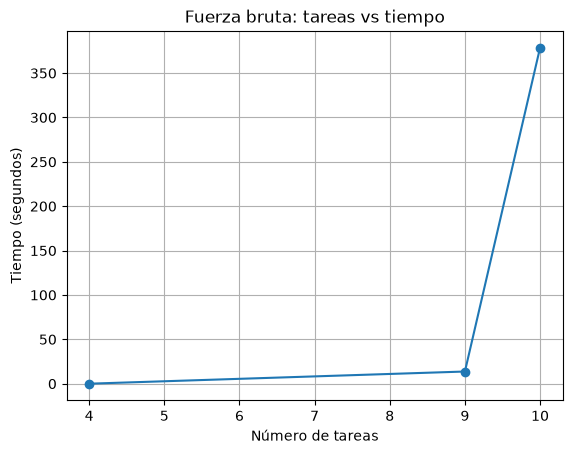

In [40]:
import matplotlib.pyplot as plt

tareas = [4, 9, 10]
tiempos = [0.0001, 13.7220, 378.6247]

plt.plot(tareas, tiempos, marker="o")
plt.xlabel("Número de tareas")
plt.ylabel("Tiempo (segundos)")
plt.title("Fuerza bruta: tareas vs tiempo")
plt.grid(True)
plt.savefig("fuerza_bruta_tiempos.png", dpi=150)
plt.show()